In [1]:
import numpy as np
import pandas as pd 

In [2]:
df = pd.read_csv("../Data/diabetes.csv")

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.corr()['Outcome']

Pregnancies                 0.221898
Glucose                     0.466581
BloodPressure               0.065068
SkinThickness               0.074752
Insulin                     0.130548
BMI                         0.292695
DiabetesPedigreeFunction    0.173844
Age                         0.238356
Outcome                     1.000000
Name: Outcome, dtype: float64

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
X_train , X_test ,y_train ,y_test = train_test_split(df.drop(columns = ['Outcome']) , df['Outcome'] , test_size = 0.2 , random_state = 42)

In [7]:
from sklearn.preprocessing import StandardScaler

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test )

In [9]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Dropout

In [10]:
model = Sequential([
    Dense(32,  activation = 'relu' , input_dim =8),
    Dropout(0.2),
    Dense(1 , activation = 'sigmoid')
])

model.compile(optimizer = 'adam' , loss = 'binary_crossentropy' , metrics = ['accuracy'])

c:\Users\gdeep\anaconda3\envs\100DaysML_311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.fit(X_train_scaled, y_train , validation_split = 0.2 , batch_size = 32 , epochs = 100)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.5601 - loss: 0.7098 - val_accuracy: 0.5935 - val_loss: 0.6856
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5804 - loss: 0.6714 - val_accuracy: 0.6423 - val_loss: 0.6521
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6477 - loss: 0.6317 - val_accuracy: 0.6911 - val_loss: 0.6217
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6599 - loss: 0.6192 - val_accuracy: 0.7317 - val_loss: 0.5991
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6802 - loss: 0.5958 - val_accuracy: 0.7317 - val_loss: 0.5797
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7210 - loss: 0.5757 - val_accuracy: 0.7480 - val_loss: 0.5676
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7108 - loss: 0.5599 - val_accuracy: 0.7642 - val_loss: 0.5525
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7393 - loss: 0.5429 - val_accuracy: 0.764

In [12]:
import kerastuner as kt

C:\Users\gdeep\AppData\Local\Temp\ipykernel_8924\1654478174.py:1: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  import kerastuner as kt


In [16]:
def build_model(hp):
    model = Sequential()
    model.add(Dense(32 , activation = 'relu', input_dim = 8)),
    model.add(Dense(1 , activation = 'sigmoid'))
    
    model.compile(optimizer = hp.Choice('optimizer' , values = ['adam' , 'sgd' ,'rmsprop' , 'adadelta']) , loss="binary_crossentropy", metrics = ['accuracy'])
    return model


In [17]:
tuner = kt.RandomSearch(build_model , objective = 'val_accuracy' , max_trials = 5, overwrite = True)

c:\Users\gdeep\anaconda3\envs\100DaysML_311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
tuner.search(X_train_scaled , y_train , epochs = 5 , validation_data = (X_test_scaled , y_test))

Trial 4 Complete [00h 00m 03s]
val_accuracy: 0.7922077775001526

Best val_accuracy So Far: 0.7922077775001526
Total elapsed time: 00h 00m 12s


In [19]:
tuner.get_best_hyperparameters()[0].values

{'optimizer': 'adam'}

In [20]:
model = tuner.get_best_models(num_models = 1)[0]

c:\Users\gdeep\anaconda3\envs\100DaysML_311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\gdeep\anaconda3\envs\100DaysML_311\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
model.fit(X_train_scaled, y_train ,epochs = 100 , batch_size = 32 , initial_epoch = 6 ,validation_data =(X_test_scaled , y_test))

Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7606 - loss: 0.5118 - val_accuracy: 0.7792 - val_loss: 0.5183
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7638 - loss: 0.4970 - val_accuracy: 0.7857 - val_loss: 0.5099
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7704 - loss: 0.4849 - val_accuracy: 0.7987 - val_loss: 0.5053
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7769 - loss: 0.4761 - val_accuracy: 0.7922 - val_loss: 0.5030
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7801 - loss: 0.4691 - val_accuracy: 0.7792 - val_loss: 0.5001
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7785 - loss: 0.4628 - val_accuracy: 0.7662 - val_loss: 0.4993
Epoch 13/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7801 - loss: 0.4586 - val_accuracy: 0.7662 - val_loss: 0.4993
Epoch 14/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7785 - loss: 0.4544 - val_accuracy: 

## Tuning neurons

In [34]:
def build_model(hp):
    model = Sequential()
    units = hp.Int('units' , min_value = 8 , max_value = 128 , step = 8)
    model.add(Dense(units = units , activation = 'relu' , input_dim = 8))
    model.add(Dense(1 , activation = 'sigmoid'))
    
    model.compile(optimizer = 'rmsprop' , loss = 'binary_crossentropy' , metrics = ['accuracy'])
                  
    return model

In [35]:
tuner = kt.RandomSearch(build_model , objective = 'val_accuracy' , max_trials = 5 , directory = 'neuron')


c:\Users\gdeep\anaconda3\envs\100DaysML_311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [38]:
tuner.search(X_train_scaled ,y_train , epochs = 5 ,validation_data = (X_test_scaled , y_test))

Trial 5 Complete [00h 00m 03s]
val_accuracy: 0.7922077775001526

Best val_accuracy So Far: 0.798701286315918
Total elapsed time: 00h 02m 12s


In [40]:
tuner.get_best_hyperparameters()[0].values

{'units': 120}

In [41]:
model = tuner.get_best_models(num_models= 1)[0]

c:\Users\gdeep\anaconda3\envs\100DaysML_311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\gdeep\anaconda3\envs\100DaysML_311\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_sprop', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(store)


In [43]:
model.fit(X_train_scaled , y_train , batch_size = 32 , epochs = 100 , initial_epoch = 6)

Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8388 - loss: 0.3735 
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8274 - loss: 0.3725
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8355 - loss: 0.3728 
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8339 - loss: 0.3723 
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8404 - loss: 0.3715 
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8371 - loss: 0.3716 
Epoch 13/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8420 - loss: 0.3702 
Epoch 14/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8388 - loss: 0.3694 
Epoch 15/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8453 - loss: 0.3696 
Epoch 16/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8355 - loss: 0.3694
Epoch 17/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8306 - loss: 0.3699 
Epoch 18/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/s

## MULTI PARAMS

In [51]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

def build_model(hp):
    model = Sequential([Input(shape=(X_train.shape[1],))])
    

    for i in range(hp.Int("num_layers", min_value=1, max_value=10)):
        model.add(Dense(
            units=hp.Int('units_' + str(i), min_value=8, max_value=128, step=8),
            activation=hp.Choice('activation_' + str(i), values=["relu", "tanh", "sigmoid"])
        ))

    model.add(Dense(1, activation='sigmoid'))
    
    model.compile(
        optimizer=hp.Choice('optimizer', values=['rmsprop', 'adam', 'sgd', 'nadam', 'adadelta']),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    return model

In [52]:
tuner = kt.RandomSearch(build_model , objective = 'val_accuracy' , max_trials = 3 , directory = 'mydir' , project_name = 'final')

In [53]:
tuner.search(X_train_scaled , y_train , epochs = 5 , validation_data = (X_test_scaled , y_test))

Trial 3 Complete [00h 00m 04s]
val_accuracy: 0.7597402334213257

Best val_accuracy So Far: 0.7597402334213257
Total elapsed time: 00h 00m 14s


In [54]:
tuner.get_best_hyperparameters()[0].values

{'num_layers': 1,
 'units_0': 88,
 'activation_0': 'relu',
 'optimizer': 'nadam',
 'units_1': 96,
 'activation_1': 'sigmoid',
 'units_2': 96,
 'activation_2': 'tanh',
 'units_3': 48,
 'activation_3': 'sigmoid'}

In [59]:
model = tuner.get_best_models(num_models = 1)[0]
history = model.fit(X_train_scaled, y_train , epochs = 100 , initial_epoch = 3 , validation_data = (X_test_scaled ,y_test))

Epoch 4/100


c:\Users\gdeep\anaconda3\envs\100DaysML_311\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'nadam', because it has 2 variables whereas the saved optimizer has 11 variables. 
  saveable.load_own_variables(store)


20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7720 - loss: 0.4849 - val_accuracy: 0.7662 - val_loss: 0.5104
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7720 - loss: 0.4704 - val_accuracy: 0.7662 - val_loss: 0.5061
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7801 - loss: 0.4612 - val_accuracy: 0.7662 - val_loss: 0.5024
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7752 - loss: 0.4540 - val_accuracy: 0.7597 - val_loss: 0.5028
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7801 - loss: 0.4487 - val_accuracy: 0.7662 - val_loss: 0.5024
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7801 - loss: 0.4447 - val_accuracy: 0.7597 - val_loss: 0.5044
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7834 - loss: 0.4417 - val_accuracy: 0.7597 - val_loss: 0.5059
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7850 - loss: 0.4386 - val_accuracy: 0.7532 - val_loss: 

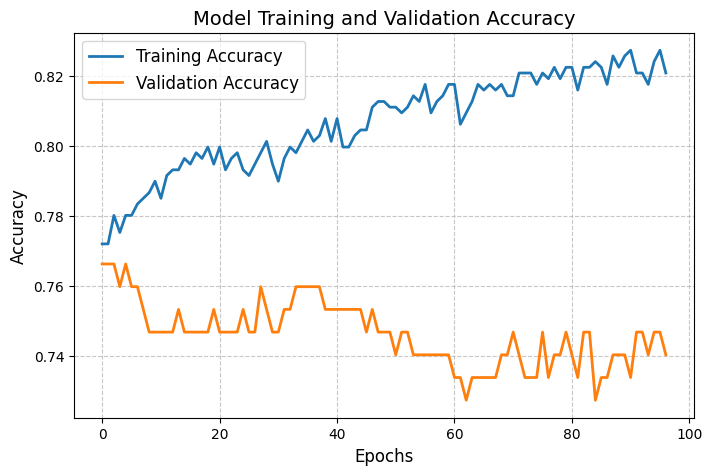

In [60]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)

plt.title('Model Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()
